In [1]:
import pandas as pd
data = pd.read_csv('/content/loan_prediction.csv')
data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [2]:
data.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [4]:
data.shape

(614, 13)

In [5]:
data.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

In [6]:
data.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [7]:
data.duplicated().sum()

np.int64(0)

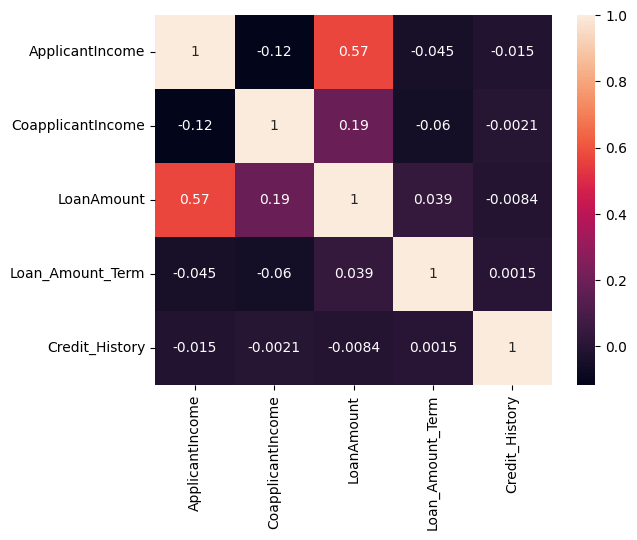

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.heatmap(data.corr(numeric_only=True), annot=True)
plt.show()

In [11]:
data['Self_Employed'] = data['Self_Employed'].fillna(method='ffill')
data

/tmp/ipykernel_1223/260314165.py:1: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data['Self_Employed'] = data['Self_Employed'].fillna(method='ffill')


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [12]:
data['LoanAmount'] = data['LoanAmount'].fillna(data['LoanAmount'].mean)

In [13]:
data['Loan_Amount_Term'] = data['Loan_Amount_Term'].fillna(data['Loan_Amount_Term'].mean)

In [14]:
data['Credit_History'] = data['Credit_History'].fillna(data['Credit_History'].mean)

In [15]:
data.isnull().sum()

,0
Loan_ID,0
Gender,0
Married,0
Dependents,15
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


In [16]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [17]:
data.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

In [18]:
features=[

    'Education',
    'Self_Employed',
    'ApplicantIncome',
    'CoapplicantIncome',
    'LoanAmount',
    'Loan_Amount_Term',
    'Credit_History'
]
X = data[features]
y = data['Loan_Status']
y= y.map({
    'Y':1,
    'N':0
})

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [20]:
X_train

,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
83,Graduate,No,6000,2250.0,265.0,360.0,<bound method Series.mean of 0 1.0\n1 ...
90,Graduate,No,2958,2900.0,131.0,360.0,1.0
227,Graduate,No,6250,1695.0,210.0,360.0,1.0
482,Graduate,No,2083,3150.0,128.0,360.0,1.0
464,Graduate,No,4166,0.0,98.0,360.0,0.0
...,...,...,...,...,...,...,...
71,Not Graduate,Yes,1875,1875.0,97.0,360.0,1.0
106,Graduate,No,11417,1126.0,225.0,360.0,1.0
270,Graduate,No,3237,0.0,30.0,360.0,1.0
435,Graduate,No,10047,0.0,<bound method Series.mean of 0 NaN\n1 ...,240.0,1.0


In [21]:
y_train

,Loan_Status
83,0
90,1
227,1
482,1
464,0
...,...
71,1
106,1
270,1
435,1


In [22]:
model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3)


for col in ['LoanAmount', 'Loan_Amount_Term', 'Credit_History']:

    X_train[col] = pd.to_numeric(X_train[col], errors='coerce')
    X_test[col] = pd.to_numeric(X_test[col], errors='coerce')

    mean_val_train = X_train[col].mean()
    X_train[col] = X_train[col].fillna(mean_val_train)
    X_test[col] = X_test[col].fillna(mean_val_train)
categorical_cols_to_encode = [col for col in X_train.select_dtypes(include='object').columns if col in ['Education', 'Self_Employed']]

if categorical_cols_to_encode:

    X_combined = pd.concat([X_train, X_test], axis=0)
    X_combined_encoded = pd.get_dummies(X_combined, columns=categorical_cols_to_encode, drop_first=True)


    X_train = X_combined_encoded.iloc[:len(X_train)]
    X_test = X_combined_encoded.iloc[len(X_train):]

model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [23]:
predicted_model = model.predict(X_test)
accuracy = accuracy_score(predicted_model, y_test)
print("Accuracy:", accuracy)

Accuracy: 0.7723577235772358


In [24]:
import pandas as pd


new_data_values = {
    'Education': 'Graduate',
    'Self_Employed': 'Yes',
    'ApplicantIncome': 4583,
    'CoapplicantIncome': 0.0,
    'LoanAmount': 133.0,
    'Loan_Amount_Term': 360.0,
    'Credit_History': 0.0
}

new_input_df = pd.DataFrame([new_data_values])

categorical_cols_for_prediction = ['Education', 'Self_Employed']

new_input_encoded = pd.get_dummies(new_input_df, columns=categorical_cols_for_prediction, drop_first=True)


final_input_for_prediction = new_input_encoded.reindex(columns=X_train.columns, fill_value=0)


new_prediction = model.predict(final_input_for_prediction)

print("New Prediction:", new_prediction)

New Prediction: [0]
